In [1]:
import pandas as pd

df = pd.read_csv("../data/cs-training.csv", index_col=0)
print("Размер датасета:", df.shape)
df.head()

Размер датасета: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
print("Число пропусков:")
print(df.isna().sum())
print()
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

Число пропусков:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


In [3]:
X = df.drop(columns=["SeriousDlqin2yrs"])

In [4]:
y = df["SeriousDlqin2yrs"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print()
print(y_train.value_counts(normalize=True), y_test.value_counts(normalize=True))

(120000, 10) (30000, 10) (120000,) (30000,)

SeriousDlqin2yrs
0    0.933158
1    0.066842
Name: proportion, dtype: float64 SeriousDlqin2yrs
0    0.933167
1    0.066833
Name: proportion, dtype: float64


In [6]:
mInc = X_train["MonthlyIncome"].median()
mDep = X_train["NumberOfDependents"].median()

In [7]:
X_train["MonthlyIncome"] = X_train["MonthlyIncome"].fillna(mInc)
X_train["NumberOfDependents"] = X_train["NumberOfDependents"].fillna(mDep)
X_test["MonthlyIncome"] = X_test["MonthlyIncome"].fillna(mInc)
X_test["NumberOfDependents"] = X_test["NumberOfDependents"].fillna(mDep)

# Baseline: LofisticRegression

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
print(type(X_train_scaled))
X_test_scaled = scaler.transform(X_test)


<class 'pandas.DataFrame'>


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

probabilities = model.predict_proba(X_test_scaled)[:,1]


In [10]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, probabilities)

gini = 2 * auc - 1

print("AUC:", auc, "   GINI:", gini*100)

AUC: 0.6950308369102249    GINI: 39.006167382044985


# Challenger: CatBoostClassifier

In [11]:
from catboost import CatBoostClassifier

catboost = CatBoostClassifier(iterations=500, learning_rate=0.05, eval_metric="AUC", random_seed=67, verbose=100)
catboost.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=50)
probabilities = catboost.predict_proba(X_test)[:,1]

0:	test: 0.8320007	best: 0.8320007 (0)	total: 183ms	remaining: 1m 31s
100:	test: 0.8644952	best: 0.8644952 (100)	total: 3.25s	remaining: 12.9s
200:	test: 0.8659589	best: 0.8659589 (200)	total: 6.35s	remaining: 9.44s
300:	test: 0.8666188	best: 0.8666337 (288)	total: 9.36s	remaining: 6.19s
400:	test: 0.8669402	best: 0.8669477 (399)	total: 12.3s	remaining: 3.04s
499:	test: 0.8670247	best: 0.8670697 (493)	total: 15.2s	remaining: 0us

bestTest = 0.8670697163
bestIteration = 493

Shrink model to first 494 iterations.


In [12]:
auc = roc_auc_score(y_test, probabilities)

gini = 2 * auc - 1

print("AUC:", auc, "   GINI:", gini*100)

AUC: 0.8670697163146786    GINI: 73.4139432629357


In [13]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, probabilities)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)
best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])
best_f1 = float(f1_scores[best_index])

print(f"Оптимальный порог: {best_threshold:.4f}")
print(f"Лучший F1-Score: {best_f1:.4f}")

Оптимальный порог: 0.1843
Лучший F1-Score: 0.4470


RevolvingUtilizationOfUnsecuredLines    32.588272
NumberOfTime30-59DaysPastDueNotWorse    13.870509
NumberOfTimes90DaysLate                 10.886032
age                                      9.927433
DebtRatio                                7.823807
NumberOfOpenCreditLinesAndLoans          7.077288
NumberOfTime60-89DaysPastDueNotWorse     6.832166
MonthlyIncome                            5.458521
NumberRealEstateLoansOrLines             4.142838
NumberOfDependents                       1.393136
dtype: float64

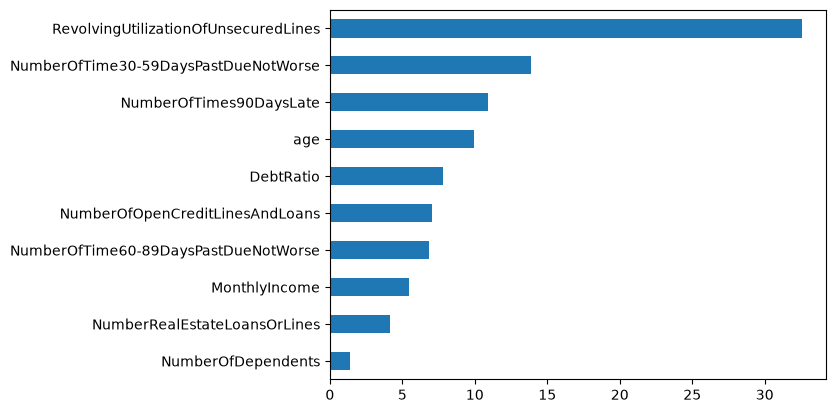

In [20]:
importance_scores = pd.Series(catboost.get_feature_importance(), index=X_train.columns).sort_values()
importance_scores.plot(kind="barh")
importance_scores.sort_values(ascending=False)

In [15]:
# catboost.save_model("model.cbm")

# import json

# metadata = {"threshold": round(best_threshold,3), "defaults": {"MonthlyIncome": mInc, "NumberOfDependents": mDep}, "features": list(X_train.columns)}

# with open("config.json", "w") as js:
#     json.dump(metadata, js, indent=2)

np.int64(575)